# Task 3- Netflix Audience Rating Classification

### **Task Workflow:**
1. **Step 1: Analyze rating categories** - Explore distribution of ratings and group raw ratings into standard audience maturity levels (`Adults`, `Teens`, `Older Kids`, `Kids`).
2. **Step 2: Prepare training datasets** - Feature selection, missing value handling, TF-IDF vectorization for genres, categorical encoding, and stratified dataset splitting.
3. **Step 3: Train classification models & Hyperparameter Tuning** - Train Decision Trees and Random Forests, and optimize hyperparameters using `GridSearchCV`.
4. **Step 4: Evaluate multi-class performance** - Multi-class classification reports, confusion matrices, and feature importance analysis.
5. **Step 5: Model comparison & interactive prediction** - Synthesize accuracy metrics across models and provide an interactive prediction widget.



## **Environment Setup & Imports**

In [1]:
# Core libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer

# Tree-based Classifiers
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Multi-class Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Google Colab check
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Setup complete. Running in Google Colab: {IN_COLAB}")

Setup complete. Running in Google Colab: True


## **Step 1: Analyze Rating Categories**

In this step, we:
1. Load `Dataset.csv` and inspect raw rating values.
2. Observe that Netflix contains over 10 raw rating designations (`TV-MA`, `TV-14`, `TV-PG`, `R`, `PG-13`, `TV-Y7`, etc.).
3. Standardize these into industry-standard **Audience Rating Categories**:
   - **`Adults (18+)`**: `TV-MA`, `R`, `NC-17`, `UR`
   - **`Teens (13-14+)`**: `TV-14`, `PG-13`
   - **`Older Kids (7-12)`**: `TV-PG`, `PG`, `TV-Y7`, `TV-Y7-FV`
   - **`Kids / All Ages (0-6)`**: `TV-Y`, `TV-G`, `G`
4. Filter out unrated titles (`NR` or missing).
5. Analyze class balance and visualize category distributions across Movies and TV Shows.

In [2]:
# Load dataset
dataset_path = '/content/Dataset.csv'

try:
    df = pd.read_csv(dataset_path)
except FileNotFoundError:
    print("Dataset.csv not found in working directory. Please upload Dataset.csv.")
    if IN_COLAB:
        uploaded = files.upload()
        dataset_path = list(uploaded.keys())[0]
        df = pd.read_csv(dataset_path)

print(f"Total Entries: {len(df)}\n")
print("Raw Rating Value Frequencies:")
print(df['rating'].value_counts())

Total Entries: 8790

Raw Rating Value Frequencies:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


Cleaned Dataset Size: 8711 titles



,Count,Percentage (%)
audience_category,,
Adults,4010,46.03
Teens,2647,30.39
Older Kids,1487,17.07
Kids,567,6.51


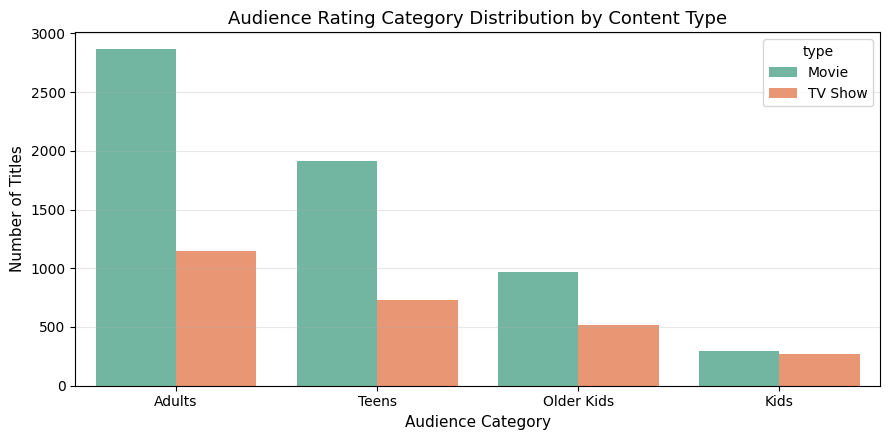

In [3]:
# Map raw ratings into 4 Audience Rating Categories
rating_map = {
    # Adults (18+)
    'TV-MA': 'Adults',
    'R': 'Adults',
    'NC-17': 'Adults',
    'UR': 'Adults',

    # Teens (13-14+)
    'TV-14': 'Teens',
    'PG-13': 'Teens',

    # Older Kids (7-12)
    'TV-PG': 'Older Kids',
    'PG': 'Older Kids',
    'TV-Y7': 'Older Kids',
    'TV-Y7-FV': 'Older Kids',

    # Kids / All Ages (0-6)
    'TV-Y': 'Kids',
    'TV-G': 'Kids',
    'G': 'Kids'
}

df_filtered = df.copy()
df_filtered['audience_category'] = df_filtered['rating'].map(rating_map)

# Drop unrated, unmapped, or missing categories
df_filtered = df_filtered.dropna(subset=['audience_category'])
print(f"Cleaned Dataset Size: {len(df_filtered)} titles\n")

# Category counts & percentages
category_counts = df_filtered['audience_category'].value_counts()
category_percentages = df_filtered['audience_category'].value_counts(normalize=True) * 100
category_stats = pd.DataFrame({'Count': category_counts, 'Percentage (%)': category_percentages.round(2)})
display(category_stats)

# Visualization of Audience Rating Categories
plt.figure(figsize=(9, 4.5))
sns.countplot(data=df_filtered, x='audience_category', hue='type', order=['Adults', 'Teens', 'Older Kids', 'Kids'], palette='Set2')
plt.title('Audience Rating Category Distribution by Content Type', fontsize=13)
plt.xlabel('Audience Category', fontsize=11)
plt.ylabel('Number of Titles', fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## **Step 2: Prepare Training Datasets**

In this step, we:
1. **Select Content Attributes:**
   - `listed_in` (Genres): Content keywords like *Horror*, *Crime*, *Romantic*, *Children*, *Animation* are strong predictors of audience maturity.
   - `type` (`Movie` vs `TV Show`): Structural format.
   - `country`: Cultural and regional classification nuances.
   - `release_year`: Temporal trends in maturity standards.
2. **Vectorize & Encode Features:**
   - `listed_in`: Transformed with `TfidfVectorizer`.
   - `type` and top `country`: Transformed with `OneHotEncoder`.
   - `release_year`: Standardized with `StandardScaler`.
3. **Encode Target Variable:**
   - `LabelEncoder` maps the 4 audience classes to `[0, 1, 2, 3]`.
4. **Split Data:**
   - 80% Training set, 20% Testing set using stratified sampling.

In [5]:
# Preprocess text and categorical attributes
for col in ['listed_in', 'country', 'type']:
    df_filtered[col] = df_filtered[col].fillna('').astype(str).str.strip()
    df_filtered[col] = df_filtered[col].replace({'Not Given': '', 'nan': ''})

# Keep top 10 countries, group remaining into 'Other'
top_countries = df_filtered['country'].value_counts().head(10).index.tolist()
df_filtered['country_grouped'] = df_filtered['country'].apply(lambda c: c if c in top_countries and c != '' else 'Other')

# Define features and target
feature_cols = ['listed_in', 'type', 'country_grouped', 'release_year']
X_raw = df_filtered[feature_cols]
y_raw = df_filtered['audience_category']

# Encode multi-class target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = list(label_encoder.classes_)
print(f"Target Label Mapping: {dict(enumerate(class_names))}\n")

# Define ColumnTransformer preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('genres_tfidf', TfidfVectorizer(token_pattern=r'(?u)\b[a-zA-Z&\-]+\b', min_df=2), 'listed_in'),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['type', 'country_grouped']),
        ('num_scaler', StandardScaler(), ['release_year'])
    ]
)

# Stratified Train-Test Split (80/20)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

# Fit preprocessor and transform data
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Train samples per class: {dict(zip(class_names, np.bincount(y_train)))}")
print(f"Test samples per class : {dict(zip(class_names, np.bincount(y_test)))}")

Target Label Mapping: {0: 'Adults', 1: 'Kids', 2: 'Older Kids', 3: 'Teens'}

X_train shape: (6968, 55) | X_test shape: (1743, 55)
Train samples per class: {'Adults': np.int64(3208), 'Kids': np.int64(454), 'Older Kids': np.int64(1189), 'Teens': np.int64(2117)}
Test samples per class : {'Adults': np.int64(802), 'Kids': np.int64(113), 'Older Kids': np.int64(298), 'Teens': np.int64(530)}


## **Step 3: Train Classification Models & Hyperparameter Tuning**

In this step, we train and tune tree-based models:
1. **Baseline Decision Tree Classifier:** Standard decision tree with default/heuristic constraints to establish initial performance.
2. **Baseline Random Forest Classifier:** Ensemble of bagged decision trees averaging probabilistic class votes.
3. **Hyperparameter Tuning via `GridSearchCV`:**
   - Optimize key parameters: `max_depth`, `min_samples_split`, `min_samples_leaf`, and `n_estimators`.
   - Uses 5-fold Stratified Cross-Validation (`cv=5`) to guard against overfitting.

In [6]:
# 1. Baseline Decision Tree
dt_baseline = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_baseline.fit(X_train, y_train)

# 2. Baseline Random Forest
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
rf_baseline.fit(X_train, y_train)

print(f"Baseline Decision Tree  - Train Acc: {dt_baseline.score(X_train, y_train)*100:.2f}% | Test Acc: {dt_baseline.score(X_test, y_test)*100:.2f}%")
print(f"Baseline Random Forest   - Train Acc: {rf_baseline.score(X_train, y_train)*100:.2f}% | Test Acc: {rf_baseline.score(X_test, y_test)*100:.2f}%")

Baseline Decision Tree  - Train Acc: 62.73% | Test Acc: 58.92%
Baseline Random Forest   - Train Acc: 74.91% | Test Acc: 60.76%


In [7]:
# 3. Hyperparameter Tuning on Random Forest using GridSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [12, 18, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'criterion': ['gini', 'entropy']
}

print("Starting Hyperparameter Tuning with 5-Fold Stratified Cross-Validation...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit GridSearch
grid_search.fit(X_train, y_train)

best_rf_model = grid_search.best_estimator_
print("\n" + "=" * 60)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 60)
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"Best 5-Fold CV Weighted F1-Score: {grid_search.best_score_:.4f}")

Starting Hyperparameter Tuning with 5-Fold Stratified Cross-Validation...
Fitting 5 folds for each of 48 candidates, totalling 240 fits

HYPERPARAMETER TUNING COMPLETED
Best Parameters Found: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best 5-Fold CV Weighted F1-Score: 0.5979


## **Step 4: Evaluate Multi-Class Prediction Performance**

In multi-class settings, accuracy alone can be misleading when classes are imbalanced. We evaluate:
1. **Per-Class Precision, Recall, and F1-Score:** Gauging whether small classes (e.g. *Kids*) are detected as reliably as dominant ones (*Adults*).
2. **Macro vs. Weighted F1:** Macro computes unweighted average across classes; weighted accounts for class frequencies.
3. **Multi-Class Confusion Matrix:** Identifying cross-category misclassifications (e.g. *Teens* confused with *Adults*).
4. **Feature Importances:** Extracting the top genre and attribute drivers.

CLASSIFICATION REPORT: DECISION TREE (BASELINE)
              precision    recall  f1-score   support

      Adults     0.6190    0.8429    0.7138       802
        Kids     0.5556    0.3982    0.4639       113
  Older Kids     0.6127    0.2919    0.3955       298
       Teens     0.5117    0.4132    0.4572       530

    accuracy                         0.5892      1743
   macro avg     0.5747    0.4866    0.5076      1743
weighted avg     0.5812    0.5892    0.5652      1743

CLASSIFICATION REPORT: RANDOM FOREST (BASELINE)
              precision    recall  f1-score   support

      Adults     0.6414    0.8342    0.7252       802
        Kids     0.5422    0.3982    0.4592       113
  Older Kids     0.6230    0.3993    0.4867       298
       Teens     0.5305    0.4264    0.4728       530

    accuracy                         0.6076      1743
   macro avg     0.5843    0.5145    0.5360      1743
weighted avg     0.5981    0.6076    0.5904      1743

CLASSIFICATION REPORT: RANDOM FORE

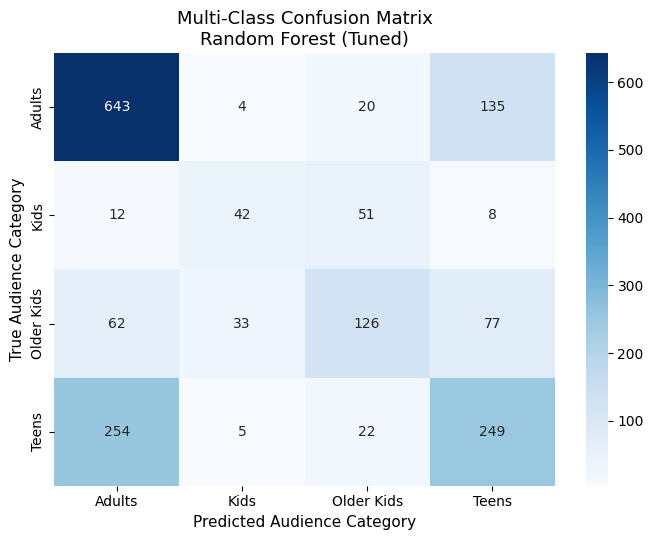

In [8]:
# Predictions dictionary
all_models = {
    'Decision Tree (Baseline)': dt_baseline,
    'Random Forest (Baseline)': rf_baseline,
    'Random Forest (Tuned)': best_rf_model
}

# Detailed Classification Reports
for name, model in all_models.items():
    y_pred = model.predict(X_test)
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 65)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# Confusion Matrix for the Best Tuned Model
best_preds = best_rf_model.predict(X_test)
cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Multi-Class Confusion Matrix\nRandom Forest (Tuned)', fontsize=13)
plt.xlabel('Predicted Audience Category', fontsize=11)
plt.ylabel('True Audience Category', fontsize=11)
plt.tight_layout()
plt.show()

/tmp/ipykernel_590/787364504.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances, y=top_features, palette='viridis')


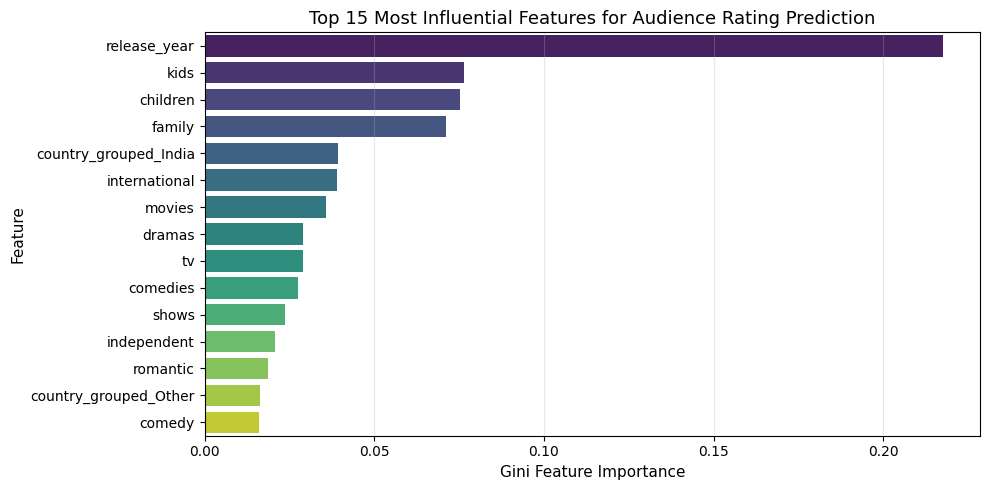

In [9]:
# Feature Importance Analysis
# Extract feature names from ColumnTransformer
tfidf_feature_names = preprocessor.named_transformers_['genres_tfidf'].get_feature_names_out()
ohe_feature_names = preprocessor.named_transformers_['cat_ohe'].get_feature_names_out()
all_feature_names = list(tfidf_feature_names) + list(ohe_feature_names) + ['release_year']

# Retrieve importances from best random forest model
importances = best_rf_model.feature_importances_
top_indices = np.argsort(importances)[::-1][:15]

top_features = [all_feature_names[i] for i in top_indices]
top_importances = importances[top_indices]

plt.figure(figsize=(10, 5))
sns.barplot(x=top_importances, y=top_features, palette='viridis')
plt.title('Top 15 Most Influential Features for Audience Rating Prediction', fontsize=13)
plt.xlabel('Gini Feature Importance', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## **Step 5: Compare Model Accuracy & Interactive Predictor**

We compile a comprehensive performance comparison across all models and test predictions interactively.

FINAL MODEL PERFORMANCE BENCHMARK


,Model,Test Accuracy (%),Macro F1-Score,Weighted F1-Score
0,Random Forest (Tuned),60.81,0.5344,0.5963
1,Random Forest (Baseline),60.76,0.5360,0.5904
2,Decision Tree (Baseline),58.92,0.5076,0.5652


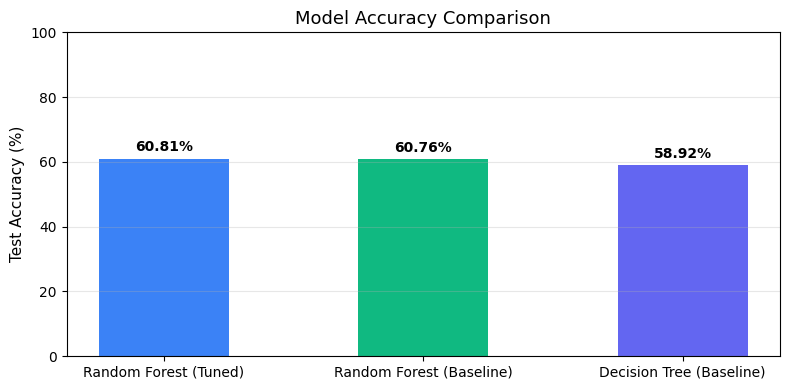

In [10]:
# Model Performance Summary Table
comparison_list = []
for name, model in all_models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    comparison_list.append({
        'Model': name,
        'Test Accuracy (%)': round(acc * 100, 2),
        'Macro F1-Score': round(macro_f1, 4),
        'Weighted F1-Score': round(weighted_f1, 4)
    })

comparison_df = pd.DataFrame(comparison_list).sort_values(by='Test Accuracy (%)', ascending=False).reset_index(drop=True)
print("=" * 70)
print("FINAL MODEL PERFORMANCE BENCHMARK")
print("=" * 70)
display(comparison_df)

# Comparison Bar Plot
plt.figure(figsize=(8, 4))
bars = plt.bar(comparison_df['Model'], comparison_df['Test Accuracy (%)'], color=['#3b82f6', '#10b981', '#6366f1'], width=0.5)
plt.title('Model Accuracy Comparison', fontsize=13)
plt.ylabel('Test Accuracy (%)', fontsize=11)
plt.ylim(0, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## **Interactive Audience Rating Predictor**

Input metadata attributes below to predict the appropriate audience rating category:

In [11]:
#@title Interactive Audience Category Predictor
input_genres = "Children & Family Movies, Comedies" #@param {type:"string"}
input_type = "Movie" #@param ["Movie", "TV Show"]
input_country = "United States" #@param ["United States", "India", "United Kingdom", "Pakistan", "Canada", "Japan", "South Korea", "France", "Other"]
input_release_year = 2021 #@param {type:"integer"}

# Format input dataframe
user_input = pd.DataFrame([{
    'listed_in': input_genres,
    'type': input_type,
    'country_grouped': input_country,
    'release_year': input_release_year
}])

# Transform features and predict using best model
user_features = preprocessor.transform(user_input)
pred_idx = best_rf_model.predict(user_features)[0]
pred_probs = best_rf_model.predict_proba(user_features)[0]
predicted_category = class_names[pred_idx]

print("=" * 60)
print("AUDIENCE RATING CLASSIFICATION RESULT")
print("=" * 60)
print(f"Predicted Audience Category : {predicted_category}")
print("\nClass Confidence Breakdown:")
for c_name, prob in zip(class_names, pred_probs):
    print(f" - {c_name:12}: {prob*100:5.2f}%")
print("=" * 60)

AUDIENCE RATING CLASSIFICATION RESULT
Predicted Audience Category : Older Kids

Class Confidence Breakdown:
 - Adults      :  0.03%
 - Kids        : 18.11%
 - Older Kids  : 80.85%
 - Teens       :  1.01%
